In [3]:
# ['pandas','sklearn','matplotlib','jupyter','lime']

import sys
sys.path.insert(0, 'C:/EnergyPlusV22-2-0/')
from pyenergyplus.api import EnergyPlusAPI

import pyenergyplus

import os
import shutil
import sys
import datetime

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import lime
import shap

In [7]:
# constants and parameters
dynamic_electricity_price = [1,1,1,1,1,1]
dynamic_weather = []
dynamic_battery = []
dynamic_PV = []
dynamic_occupancy = []
transportation_data = []
# realize cosimulation among different buildings
# VOLTTRON?

In [4]:
%matplotlib notebook
# or nbagg

<IPython.core.display.Javascript object>


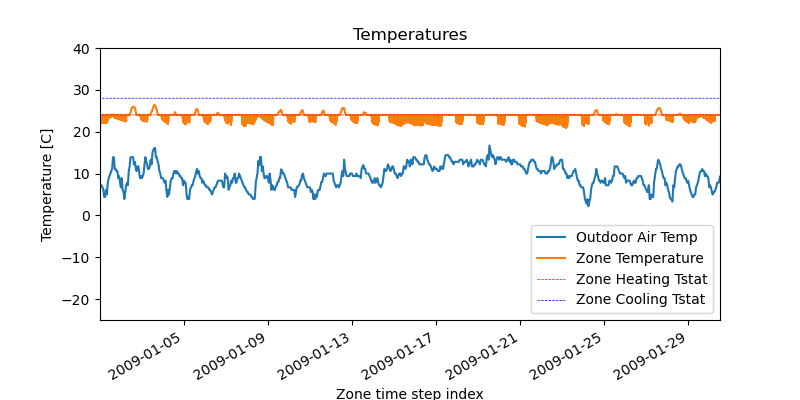

CPU times: total: 4.69 s
Wall time: 4.83 s


In [5]:
%%time
x = []
y_outdoor = []
y_zone = []
y_htg = []
y_clg = []

years = []
months = []
days = []
hours = []
minutes = []
current_times = []
actual_date_times = []
actual_times = []

fig, ax = plt.subplots(figsize=(8, 4), num='Real time plot')
h1, = ax.plot(x, y_outdoor, label="Outdoor Air Temp")
h2, = ax.plot(x, y_zone, label="Zone Temperature")
h_htg, = ax.plot(x, y_htg, label='Zone Heating Tstat', linestyle='--', color='r', linewidth=0.5)
h_clg, = ax.plot(x, y_clg, label='Zone Cooling Tstat', linestyle='--', color='blue', linewidth=0.5)

ax.set_title('Temperatures')
ax.set_xlabel('Zone time step index')
ax.set_ylabel('Temperature [C]')
ax.legend(loc='lower right')
ax.set_ylim(-25, 40)
fig.autofmt_xdate()

# plt.show(False)
#plt.draw()
    

filename_to_run = "EnergyPlus_models/RefBldgSmallOfficeNew2004_v1.4_7.2_2B_USA_AZ_PHOENIX/RefBldgSmallOfficeNew2004_v1.4_7.2_2B_USA_AZ_PHOENIX.idf"
weather_file = 'epw_weather_files/USA_CA_San.Francisco.Intl.AP.724940_TMY3.epw'
result_folder = 'results/RefBldgSmallOfficeNew2004_v1.4_7.2_2B_USA_AZ_PHOENIX/'
zone_name = "Perimeter_ZN_1"

got_handles = False
oa_temp_handle = -1
zone_temp_handle = -1
zone_htg_tstat_handle = -1
zone_clg_tstat_handle = -1
count = 0
plot_update_interval = 250  # time steps

def update_line():
    
    
    #hl.set_data(x, y_outdoor)
    #h2.set_data(x, y_zone)
    
    h1.set_xdata(x)
    h1.set_ydata(y_outdoor)
    h2.set_xdata(x)
    h2.set_ydata(y_zone)
    h_htg.set_xdata(x)
    h_htg.set_ydata(y_htg)
    h_clg.set_xdata(x)
    h_clg.set_ydata(y_clg)
    
    ax.set_xlim(x[0], x[-1])
    #ax.set_ylim(min(y_outdoor + y_zone), max(y_outdoor + y_zone))
    #ax.autoscale_view()
    fig.canvas.draw()
    


def callback_function(state_argument):
    global count, got_handles, oa_temp_handle, zone_temp_handle, zone_htg_tstat_handle, zone_clg_tstat_handle, handle_clgsetp,  handle_htgsetp
    
    if not got_handles:
        if not api.exchange.api_data_fully_ready(state_argument):
            return
        
        # Variable handles
        oa_temp_handle = api.exchange.get_variable_handle(state_argument, u"SITE OUTDOOR AIR DRYBULB TEMPERATURE", u"ENVIRONMENT")
        zone_temp_handle = api.exchange.get_variable_handle(state_argument, "Zone Mean Air Temperature", zone_name)
        zone_htg_tstat_handle = api.exchange.get_variable_handle(state_argument, "Zone Thermostat Heating Setpoint Temperature", zone_name)
        zone_clg_tstat_handle = api.exchange.get_variable_handle(state_argument, "Zone Thermostat Cooling Setpoint Temperature", zone_name)
        
        # Actuarator handles
        handle_clgsetp = api.exchange.get_actuator_handle(state_argument, "Schedule:Compact", "Schedule Value", "CLGSETP_SCH")
        handle_htgsetp = api.exchange.get_actuator_handle(state_argument, "Schedule:Compact", "Schedule Value", "HTGSETP_SCH")        
        
        if -1 in [oa_temp_handle, zone_temp_handle, zone_htg_tstat_handle, zone_clg_tstat_handle, handle_clgsetp,  handle_htgsetp]:
            print("***Invalid handles, check spelling and sensor/actuator availability")
            sys.exit(1)
        got_handles = True
        
    if api.exchange.warmup_flag(state_argument):
        return
    count += 1

    # get variables
    oa_temp = api.exchange.get_variable_value(state_argument, oa_temp_handle)
    y_outdoor.append(oa_temp)
    
    zone_temp = api.exchange.get_variable_value(state_argument, zone_temp_handle)
    y_zone.append(zone_temp)
    
    zone_htg_tstat = api.exchange.get_variable_value(state_argument, zone_htg_tstat_handle)
    y_htg.append(zone_htg_tstat)
    
    zone_clg_tstat = api.exchange.get_variable_value(state_argument, zone_clg_tstat_handle)
    y_clg.append(zone_clg_tstat)
    
    # get information/data from PV, energy storage, weather, electricity price, and other buildings
    # TODO
    
    # controls
    api.exchange.set_actuator_value(state_argument, handle_clgsetp, 28)
    api.exchange.set_actuator_value(state_argument, handle_htgsetp, 24)
    
    # Time
    year = api.exchange.year(state)
    month = api.exchange.month(state)
    day = api.exchange.day_of_month(state)
    hour = api.exchange.hour(state)
    minute = api.exchange.minutes(state)
    current_time = api.exchange.current_time(state)
    actual_date_time = api.exchange.actual_date_time(state)
    actual_time = api.exchange.actual_time(state)
                    
    # Year is bogus, seems to be reading the weather file year instead...         
    # So harcode it to 2009
    year = 2009
    years.append(year)
    months.append(month)
    days.append(day)
    hours.append(hour)
    minutes.append(minute)
    
    current_times.append(current_time)
    actual_date_times.append(actual_date_time)
    actual_times.append(actual_time)
    
    timedelta = datetime.timedelta()
    if hour >= 24.0:
        hour = 23.0
        timedelta += datetime.timedelta(hours=1)
    if minute >= 60.0:
        minute = 59
        timedelta += datetime.timedelta(minutes=1)
    
    dt = datetime.datetime(year=year, month=month, day=day, hour=hour, minute=minute)
    dt += timedelta
    x.append(dt)
    
    if count % plot_update_interval == 0:
        update_line()

api = EnergyPlusAPI()
state = api.state_manager.new_state()

api.runtime.callback_begin_zone_timestep_after_init_heat_balance(state, callback_function)
api.runtime.run_energyplus(state,
    [
        '-w', weather_file,
        '-d', result_folder,
        filename_to_run
    ]
)

# If you need to call run_energyplus again, then reset the state first
api.state_manager.reset_state(state)